# 07_final_calibrated_pipeline.ipynb — โมเดลสุดท้ายที่พร้อมเขียนรายงาน

โน้ตบุ๊กนี้เอาผลจาก `06_new_experiments.ipynb` มาปรับใช้กับโมเดลจริง (ไม่ใช่ RF ทดสอบเร็วๆ):

1. เทรน stacking model (RF+XGBoost tuned จาก `05_improved_pipeline4.ipynb`) เหมือนเดิม
2. **Calibrate ด้วย isotonic regression** — แก้ปัญหา probability inflate ที่เจอใน Experiment C ของ notebook 06
3. **คำนวณ threshold ใหม่** จาก calibrated probability (threshold เดิมใน 05 คำนวณจาก probability ที่ยังไม่ calibrate)
4. Classification report + confusion matrix เวอร์ชันสุดท้าย
5. **Fairness analysis ด้วยโมเดลตัวจริง** (ไม่ใช่ RF ทดสอบ)
6. บันทึกโมเดลสุดท้ายพร้อม threshold ที่แนะนำ

**หมายเหตุเรื่อง imbalance technique**: จาก Experiment A ใน notebook 06 พบว่าไม่มีเทคนิคไหน (RUS, SMOTEENN, SMOTETomek, BalancedRandomForest, EasyEnsemble) เอาชนะ `class_weight="balanced"` ที่เลือกไว้เดิมได้จริง (ต่างกันอยู่ในช่วง noise ของ CV) — จึง**คงใช้ class_weight="balanced" ต่อ** ไม่เปลี่ยน pipeline หลัก

**หมายเหตุเรื่อง LACE score**: จาก Experiment B พบว่า LACE-like composite score ไม่เพิ่ม PR-AUC อย่างมีนัยสำคัญ (+0.0013 อยู่ในช่วง noise) จึง**ไม่ใส่ถาวรใน feature set** — จะเขียนเป็น negative finding ในรายงานแทน

ก่อนรัน: `pip install imbalanced-learn shap xgboost` ถ้ายังไม่มี

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report, brier_score_loss,
)
from xgboost import XGBClassifier

RANDOM_STATE = 42


## 2. Load & Clean Data (เหมือนเดิมทุกขั้นตอน)

In [2]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df.shape}")

df = df[df["gender"] != "Unknown/Invalid"]

death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]

df = df.sort_values(["patient_nbr", "encounter_id"])
df = df.reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")

df["readmitted_raw"] = df["readmitted"]  

# แปลง target ทันทีหลัง cleaning (เหมือนที่แก้ไว้ใน 06_new_experiments.ipynb กัน error ลำดับเซลล์)
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)
print(df["readmitted"].value_counts(normalize=True))


Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)
readmitted
0    0.886108
1    0.113892
Name: proportion, dtype: float64


## 3. Feature Engineering (เหมือน 05_improved_pipeline4.ipynb — ไม่ใส่ LACE score ถาวร)

In [3]:
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]

df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
df["change_flag"] = (df["change"] == "Ch").astype(int)
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)


In [4]:
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})
df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

drop_cols = ["weight", "payer_code", "encounter_id"]
df.drop(columns=drop_cols, inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(
    df["medical_specialty"].isin(top_specialties), "Other"
)
df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Dropping constant columns: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)


Dropping constant columns: ['examide', 'citoglipton']


## 4. Encode + Train/Test Split (GroupShuffleSplit ตาม patient_nbr — เหมือนเดิม)

In [5]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"

X = df.drop(columns=[TARGET_COL, "readmitted_raw"])
y = df[TARGET_COL]

feature_cols = [c for c in X.columns if c != GROUP_COL]
categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
if "age" in categorical_cols:
    categorical_cols.remove("age")
X = X.drop(columns=["age"])

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

# เก็บ demographic ดิบของ test set ไว้ต่างหาก (ยังไม่ encode) ไว้ใช้ตอน fairness analysis
demographic_cols_raw = df[["race", "gender", "age"]].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
demo_test = demographic_cols_raw.iloc[test_idx].reset_index(drop=True)

X_train.drop(columns=[GROUP_COL], inplace=True)
X_test.drop(columns=[GROUP_COL], inplace=True)

overlap = set(df.iloc[train_idx][GROUP_COL]) & set(df.iloc[test_idx][GROUP_COL])
print(f"Patient overlap (ต้องเป็น 0): {len(overlap)}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target rate: {y_train.mean():.4f}, Test target rate: {y_test.mean():.4f}")


Patient overlap (ต้องเป็น 0): 0
Train: (79567, 54), Test: (19773, 54)
Train target rate: 0.1140, Test target rate: 0.1135


## 5. Base Models — ใช้ hyperparameter ที่ tune ไว้แล้วจาก 05_improved_pipeline4.ipynb

ใช้ `class_weight="balanced"` ตรงๆ (ไม่ resample) ตามที่สรุปไว้ใน Experiment A ของ `06_new_experiments.ipynb` ว่าเป็นตัวเลือกที่ดีที่สุดอยู่แล้ว และใช้ hyperparameter ที่ได้จาก `RandomizedSearchCV` ใน `05_improved_pipeline4.ipynb` ตรงๆ (ไม่ต้อง search ใหม่ ประหยัดเวลา)

In [6]:
# hyperparameter ที่ดีที่สุดจาก RandomizedSearchCV ใน 05_improved_pipeline4.ipynb ขั้นตอนที่ 7
rf_pipeline = RandomForestClassifier(
    n_estimators=500, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
)

xgb_pipeline = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.01, subsample=0.9,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
)

print("RF and XGBoost configured with tuned hyperparameters (no re-search needed).")


RF and XGBoost configured with tuned hyperparameters (no re-search needed).


## 6. Stacking Classifier (โครงสร้างเหมือน 05_improved_pipeline4.ipynb)

In [7]:
estimators = [("rf", rf_pipeline), ("xgboost", xgb_pipeline)]

scaled_meta_learner = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=scaled_meta_learner,
    cv=5, n_jobs=-1, passthrough=True,
)

print("Training stacking ensemble...")
stacking_model.fit(X_train, y_train)
print("Done.")

proba_uncalibrated = stacking_model.predict_proba(X_test)[:, 1]
print(f"\nUncalibrated PR-AUC : {average_precision_score(y_test, proba_uncalibrated):.4f}")
print(f"Uncalibrated ROC-AUC: {roc_auc_score(y_test, proba_uncalibrated):.4f}")
print(f"Uncalibrated Brier  : {brier_score_loss(y_test, proba_uncalibrated):.4f}")


Training stacking ensemble...
Done.

Uncalibrated PR-AUC : 0.2272
Uncalibrated ROC-AUC: 0.6748
Uncalibrated Brier  : 0.2276


## 7. Calibration — แก้ปัญหา probability inflate ที่เจอใน Experiment C

`class_weight="balanced"` ทำให้ probability ที่โมเดลให้มา**ไม่สะท้อนความจริง** (inflate สูงเกินจริง) — Brier score ที่แย่ในเซลล์ก่อนหน้ายืนยันเรื่องนี้ ใช้ `CalibratedClassifierCV(method="isotonic", cv=3)` เพื่อแก้ไข

**หมายเหตุเรื่องเวลารัน**: เซลล์นี้ refit `stacking_model` ใหม่ 3 ครั้ง (ตาม cv=3) และแต่ละครั้ง stacking เองก็มี cv=5 ข้างในอีกชั้น (nested cv) จึงอาจใช้เวลาหลายนาที ถ้าอยากให้เร็วขึ้นสามารถลด `cv=3` เป็น `cv=2` หรือ export calibration ไปทำแยกด้วย held-out set แทนได้

Calibrating (อาจใช้เวลาหลายนาทีเพราะ nested cv)...
Done.

Metric                 Uncalibrated     Calibrated
PR-AUC                       0.2272         0.2220
ROC-AUC                      0.6748         0.6727
Brier score                  0.2276         0.0961


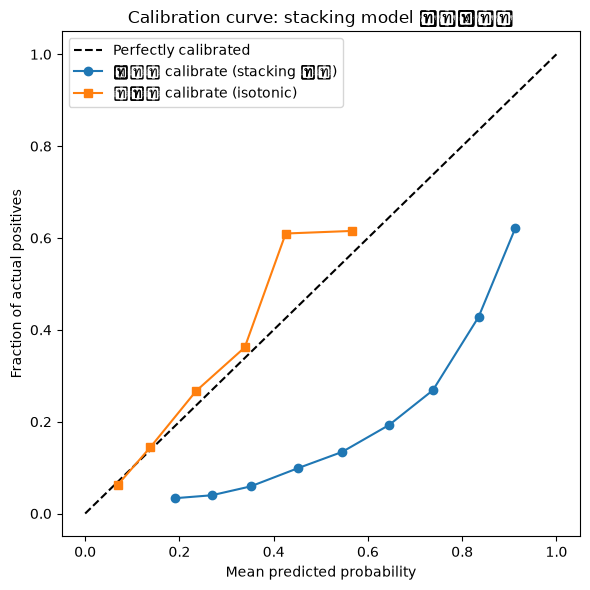

In [8]:
calibrated_stacking = CalibratedClassifierCV(stacking_model, method="isotonic", cv=3)
print("Calibrating (อาจใช้เวลาหลายนาทีเพราะ nested cv)...")
calibrated_stacking.fit(X_train, y_train)
print("Done.")

proba_calibrated = calibrated_stacking.predict_proba(X_test)[:, 1]

print(f"\n{'Metric':20s}{'Uncalibrated':>15s}{'Calibrated':>15s}")
print(f"{'PR-AUC':20s}{average_precision_score(y_test, proba_uncalibrated):>15.4f}{average_precision_score(y_test, proba_calibrated):>15.4f}")
print(f"{'ROC-AUC':20s}{roc_auc_score(y_test, proba_uncalibrated):>15.4f}{roc_auc_score(y_test, proba_calibrated):>15.4f}")
print(f"{'Brier score':20s}{brier_score_loss(y_test, proba_uncalibrated):>15.4f}{brier_score_loss(y_test, proba_calibrated):>15.4f}")

frac_pos_raw, mean_pred_raw = calibration_curve(y_test, proba_uncalibrated, n_bins=10)
frac_pos_cal, mean_pred_cal = calibration_curve(y_test, proba_calibrated, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(mean_pred_raw, frac_pos_raw, "o-", label="ก่อน calibrate (stacking ดิบ)")
plt.plot(mean_pred_cal, frac_pos_cal, "s-", label="หลัง calibrate (isotonic)")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of actual positives")
plt.title("Calibration curve: stacking model สุดท้าย")
plt.legend()
plt.tight_layout()
plt.show()


## 8. คำนวณ Threshold ใหม่จาก Calibrated Probability

Threshold เดิมใน `05_improved_pipeline4.ipynb` คำนวณจาก probability ที่ยังไม่ calibrate — คำนวณใหม่ทั้งหมดตรงนี้เพื่อให้สอดคล้องกับ probability ที่แก้แล้ว

In [9]:
def expected_cost(y_true, y_pred, cost_fn=5, cost_fp=1):
    """ต้นทุนรวมตาม False Negative (พลาดเคส readmit) และ False Positive (แจ้งเตือนเกิน)
    cost_fn=5, cost_fp=1 หมายถึงพลาดเคส readmit costly กว่าแจ้งเตือนเกิน 5 เท่า
    ปรับตามต้นทุนจริงของโรงพยาบาล/ทีมที่ใช้งาน"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn * cost_fn + fp * cost_fp

precisions, recalls, thresholds = precision_recall_curve(y_test, proba_calibrated)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
f2_scores = 5 * precisions * recalls / (4 * precisions + recalls + 1e-9)

best_th_f1 = thresholds[f1_scores[:-1].argmax()]
best_th_f2 = thresholds[f2_scores[:-1].argmax()]

cost_candidates = np.arange(0.02, 0.95, 0.01)
costs = [expected_cost(y_test, (proba_calibrated >= t).astype(int)) for t in cost_candidates]
best_th_cost = cost_candidates[np.argmin(costs)]

print(f"Threshold ใหม่ (จาก calibrated probability):")
print(f"  F1-optimal   : {best_th_f1:.4f}")
print(f"  F2-optimal   : {best_th_f2:.4f}")
print(f"  Cost-optimal : {best_th_cost:.4f}  (cost_fn=5:cost_fp=1)")

best_threshold = best_th_cost  # ค่าเริ่มต้นแนะนำ
print(f"\n>>> ใช้ cost-optimal threshold ({best_threshold:.4f}) เป็นค่าแนะนำหลัก")


Threshold ใหม่ (จาก calibrated probability):
  F1-optimal   : 0.1364
  F2-optimal   : 0.0840
  Cost-optimal : 0.1500  (cost_fn=5:cost_fp=1)

>>> ใช้ cost-optimal threshold (0.1500) เป็นค่าแนะนำหลัก


## 9. Classification Report + Confusion Matrix (เวอร์ชันสุดท้าย)

เทียบ threshold=0.5 (default) vs cost-optimal threshold ที่คำนวณใหม่จาก calibrated probability


Threshold = 0.5 (default) (threshold=0.500)
                    precision    recall  f1-score   support

Not readmitted (0)     0.8872    0.9994    0.9400     17529
    Readmitted (1)     0.6154    0.0071    0.0141      2244

          accuracy                         0.8868     19773
         macro avg     0.7513    0.5033    0.4770     19773
      weighted avg     0.8563    0.8868    0.8349     19773

Expected cost (cost_fn=5, cost_fp=1): 11150

Threshold = 0.150 (cost-optimal) (threshold=0.150)
                    precision    recall  f1-score   support

Not readmitted (0)     0.9135    0.8127    0.8602     17529
    Readmitted (1)     0.2142    0.3988    0.2787      2244

          accuracy                         0.7657     19773
         macro avg     0.5639    0.6058    0.5694     19773
      weighted avg     0.8341    0.7657    0.7942     19773

Expected cost (cost_fn=5, cost_fp=1): 10028


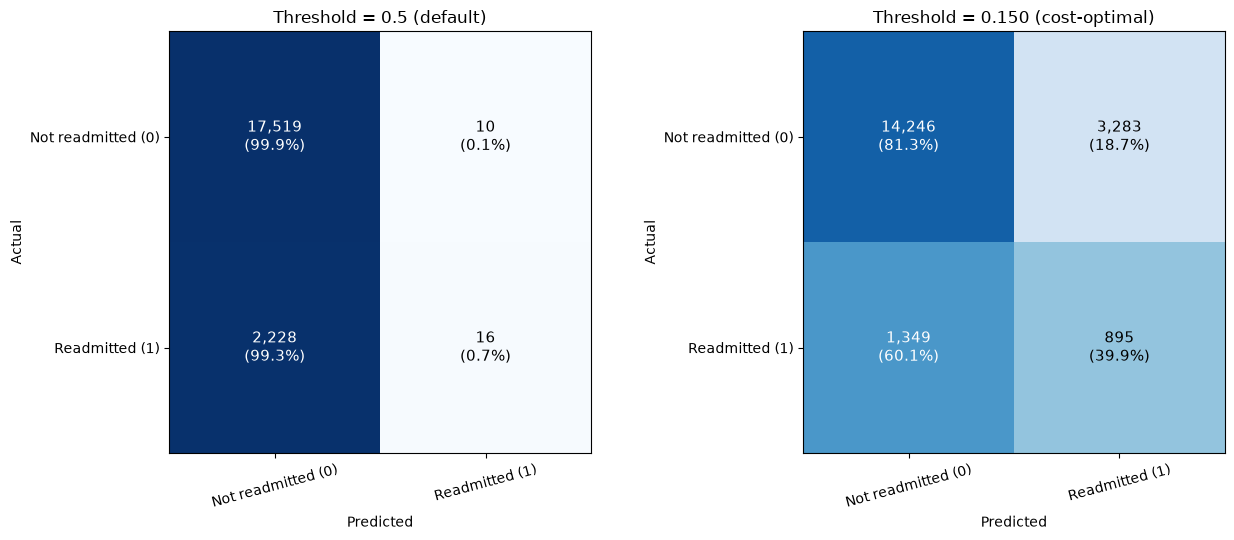

In [10]:
target_names = ["Not readmitted (0)", "Readmitted (1)"]

def report_and_plot(y_true, y_proba, threshold, title, ax):
    y_pred = (y_proba >= threshold).astype(int)
    print(f"\n{'='*60}\n{title} (threshold={threshold:.3f})\n{'='*60}")
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4))
    print(f"Expected cost (cost_fn=5, cost_fp=1): {expected_cost(y_true, y_pred)}")

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(target_names, rotation=15)
    ax.set_yticklabels(target_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            color = "white" if cm_norm[i, j] > 0.5 else "black"
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)",
                    ha="center", va="center", color=color, fontsize=11)
    return cm

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
report_and_plot(y_test, proba_calibrated, 0.5, "Threshold = 0.5 (default)", axes[0])
report_and_plot(y_test, proba_calibrated, best_threshold, f"Threshold = {best_threshold:.3f} (cost-optimal)", axes[1])
plt.tight_layout()
plt.savefig("confusion_matrix_final.png", dpi=150, bbox_inches="tight")
plt.show()


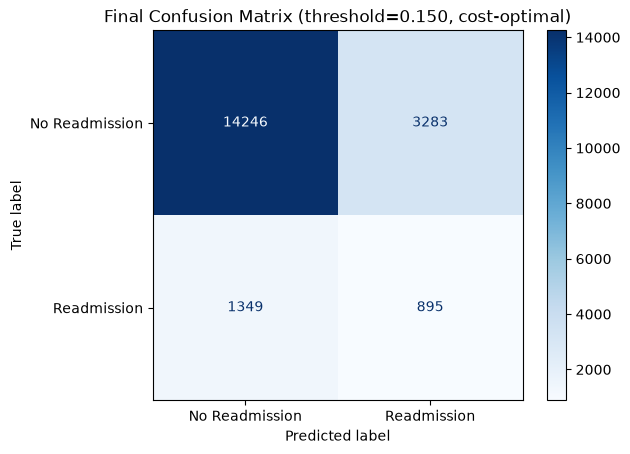

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

y_pred_final = (proba_calibrated >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmission", "Readmission"]
)

disp.plot(cmap="Blues")

plt.title(f"Final Confusion Matrix (threshold={best_threshold:.3f}, cost-optimal)")
plt.show()

## 10. Fairness / Subgroup Analysis — ด้วยโมเดลสุดท้ายจริง

รันซ้ำจาก Experiment D ใน `06_new_experiments.ipynb` แต่ใช้ `calibrated_stacking` (โมเดลตัวจริงที่ tune แล้ว) แทน RF ทดสอบ ที่ threshold ที่แนะนำ (cost-optimal)

In [12]:
def subgroup_report(y_true, y_proba, group_values, group_name, threshold=0.5, min_group_size=30):
    print(f"\n--- Subgroup performance by {group_name} (threshold={threshold:.3f}) ---")
    results = []
    for g in sorted(set(group_values)):
        mask = (group_values == g)
        if mask.sum() < min_group_size:
            continue
        y_t = y_true[mask]
        y_p = y_proba[mask]
        if y_t.nunique() < 2:
            continue
        y_pred = (y_p >= threshold).astype(int)
        results.append({
            "group": g,
            "n": int(mask.sum()),
            "base_rate": round(y_t.mean(), 4),
            "PR_AUC": round(average_precision_score(y_t, y_p), 4),
            "ROC_AUC": round(roc_auc_score(y_t, y_p), 4),
            "F2": round(fbeta_score(y_t, y_pred, beta=2, zero_division=0), 4),
            "Recall": round(recall_score(y_t, y_pred, zero_division=0), 4),
        })
    res_df = pd.DataFrame(results).sort_values("n", ascending=False)
    print(res_df.to_string(index=False))
    return res_df

y_test_reset = y_test.reset_index(drop=True)
race_report = subgroup_report(y_test_reset, proba_calibrated, demo_test["race"], "race", threshold=best_threshold)
gender_report = subgroup_report(y_test_reset, proba_calibrated, demo_test["gender"], "gender", threshold=best_threshold)
age_report = subgroup_report(y_test_reset, proba_calibrated, demo_test["age"], "age", threshold=best_threshold)

print("\n>>> เอาผลนี้ (โมเดลตัวจริง) ไปแทนที่ผลจาก RF ทดสอบใน 06_new_experiments.ipynb ในรายงานฉบับสุดท้าย")
print(">>> ให้เน้นกลุ่มที่ ROC-AUC/PR-AUC ต่ำผิดปกติ (คาดว่ายังเป็นกลุ่มอายุ 80+ เหมือนที่เจอในการทดลองก่อนหน้า)")



--- Subgroup performance by race (threshold=0.150) ---
          group     n  base_rate  PR_AUC  ROC_AUC     F2  Recall
      Caucasian 14813     0.1172  0.2339   0.6707 0.3445  0.3998
AfricanAmerican  3697     0.1079  0.1932   0.6690 0.3356  0.4160
        Missing   447     0.0716  0.1348   0.6473 0.2528  0.2812
       Hispanic   398     0.0905  0.2286   0.7627 0.3365  0.3889
          Other   302     0.1026  0.1802   0.6702 0.2711  0.2903
          Asian   116     0.0862  0.1508   0.6651 0.2632  0.3000

--- Subgroup performance by gender (threshold=0.150) ---
 group     n  base_rate  PR_AUC  ROC_AUC     F2  Recall
Female 10726     0.1145  0.2345   0.6836 0.3504  0.4137
  Male  9047     0.1123  0.2090   0.6595 0.3276  0.3809

--- Subgroup performance by age (threshold=0.150) ---
   group    n  base_rate  PR_AUC  ROC_AUC     F2  Recall
 [70-80) 4921     0.1130  0.1853   0.6581 0.3321  0.4029
 [60-70) 4356     0.1157  0.2010   0.6589 0.3187  0.3611
 [50-60) 3467     0.1087  0.2933   0.

## 11. บันทึกโมเดลสุดท้าย

In [13]:
joblib.dump(
    {
        "stacking_model_uncalibrated": stacking_model,
        "calibrated_stacking_model": calibrated_stacking,
        "best_threshold_f1": best_th_f1,
        "best_threshold_f2": best_th_f2,
        "best_threshold_cost": best_th_cost,
        "recommended_threshold": best_threshold,
        "label_encoders": label_encoders,
        "feature_names": X_train.columns.tolist(),
        "resampling_method_used": "class_weight_balanced (no resample) — ยืนยันจาก Experiment A ของ 06_new_experiments.ipynb",
        "lace_score_decision": "ทดสอบแล้วไม่ใส่ถาวร — PR-AUC gain +0.0013 อยู่ในช่วง noise (ดู Experiment B ของ 06_new_experiments.ipynb)",
        "fairness_reports": {
            "race": race_report,
            "gender": gender_report,
            "age": age_report,
        },
    },
    "../models/final_calibrated_model_v1.pkl",
)
print("Saved to ../models/final_calibrated_model_v1.pkl")
print(f"Recommended threshold (cost-optimal, calibrated): {best_threshold:.4f}")
print(f"PR-AUC (calibrated): {average_precision_score(y_test, proba_calibrated):.4f}")
print(f"Brier score (calibrated): {brier_score_loss(y_test, proba_calibrated):.4f}")


Saved to ../models/final_calibrated_model_v1.pkl
Recommended threshold (cost-optimal, calibrated): 0.1500
PR-AUC (calibrated): 0.2220
Brier score (calibrated): 0.0961


In [14]:
print("readmitted_raw" in df.columns)

True


Saved: km_curve_by_risk_tier.png

Survival probability at day 30 (= 1 - cumulative readmission risk):
  Low    : 1.0000
  Medium : 1.0000
  High   : 1.0000


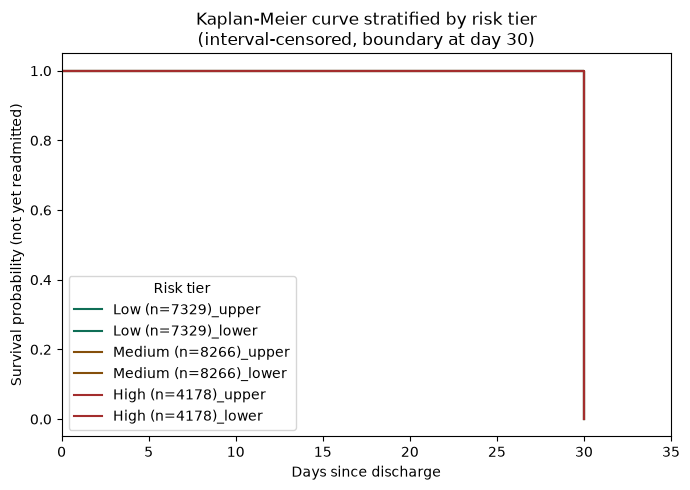

In [15]:
"""
Supplementary Survival Analysis — Kaplan-Meier curve stratified by risk tier
=============================================================================
วิเคราะห์เสริมตามที่อาจารย์แนะนำ ใช้ผลลัพธ์จาก 07_final_calibrated_pipeline.ipynb
โดยตรง ไม่ต้อง retrain โมเดลหรือแตะ pipeline หลัก

ใช้ก่อนรัน: pip install lifelines matplotlib
"""

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# ============================================================
# 1. โหลดข้อมูลและโมเดลที่ finalize แล้ว (ไม่ retrain)
# ============================================================
# หมายเหตุสำคัญ: ให้รันสคริปต์นี้เป็น cell เพิ่มเติมต่อท้ายใน
# 07_final_calibrated_pipeline.ipynb (หลัง cell 9 rerun ด้วย readmitted_raw)
# ไม่ใช่รันแยกไฟล์ .py เพราะต้องใช้ตัวแปร X_test, test_idx, df ที่มีอยู่แล้วใน notebook
#
# ก่อนรันส่วนนี้ ต้องแก้ cell 4 เพิ่มบรรทัด:
#     df["readmitted_raw"] = df["readmitted"]   # ก่อนบรรทัด binarize
# แล้ว rerun cell 4 และ cell 9 (ไม่ต้อง rerun cell 11 เป็นต้นไป ไม่ต้อง retrain)

MODEL_PATH = "final_calibrated_model_v1.pkl"
bundle = joblib.load(MODEL_PATH)
model = bundle["calibrated_stacking_model"]

# ตัวแปรเหล่านี้มาจาก notebook cell 9 โดยตรง (รันในสภาพแวดล้อมเดียวกัน ไม่ต้อง reload)
# X_test          <- จาก cell 9 (feature matrix ที่ encode แล้ว)
# test_idx        <- จาก cell 9 (index ของ test set ใน df)
# df              <- DataFrame หลัง cleaning ที่มี "readmitted_raw" (ต้องเพิ่มเองตามข้างบน)

readmitted_raw_test = df.iloc[test_idx]["readmitted_raw"].reset_index(drop=True)

# ============================================================
# 2. คำนวณ calibrated probability และจัด risk tier (เหมือนใน dashboard)
# ============================================================
THRESHOLD_LOW_MED = 0.084
THRESHOLD_MED_HIGH = 0.150

proba = model.predict_proba(X_test)[:, 1]

def get_tier(p):
    if p >= THRESHOLD_MED_HIGH:
        return "High"
    elif p >= THRESHOLD_LOW_MED:
        return "Medium"
    return "Low"

risk_tier = pd.Series([get_tier(p) for p in proba])

# ============================================================
# 3. สร้าง interval bounds จาก readmitted_raw_test
# ============================================================
lower_bound = np.where(readmitted_raw_test == "<30", 0, 30)
upper_bound = np.where(readmitted_raw_test == "<30", 30, np.inf)

# ============================================================
# 4. Fit Kaplan-Meier แยกตาม risk tier (interval-censored)
# ============================================================
tiers = ["Low", "Medium", "High"]
colors = {"Low": "#0F6E56", "Medium": "#854F0B", "High": "#A32D2D"}

fig, ax = plt.subplots(figsize=(7, 5))

kmf_results = {}
for tier in tiers:
    mask = (risk_tier == tier).values
    kmf = KaplanMeierFitter()
    kmf.fit_interval_censoring(
        lower_bound[mask], upper_bound[mask],
        label=f"{tier} (n={mask.sum()})"
    )
    kmf_results[tier] = kmf
    kmf.plot_survival_function(ax=ax, color=colors[tier])

ax.set_xlabel("Days since discharge")
ax.set_ylabel("Survival probability (not yet readmitted)")
ax.set_title("Kaplan-Meier curve stratified by risk tier\n(interval-censored, boundary at day 30)")
ax.set_xlim(0, 35)
ax.legend(title="Risk tier")
plt.tight_layout()
plt.savefig("km_curve_by_risk_tier.png", dpi=200)
print("Saved: km_curve_by_risk_tier.png")

# ============================================================
# 5. รายงานค่า survival probability ที่วันที่ 30 ของแต่ละ tier
# ============================================================
print("\nSurvival probability at day 30 (= 1 - cumulative readmission risk):")
for tier in tiers:
    kmf = kmf_results[tier]
    # หาแถวใน survival_function_ ที่ index ใกล้ 30 ที่สุด
    sf = kmf.survival_function_
    val_at_30 = sf.iloc[(sf.index.get_indexer([30], method="nearest"))[0]]
    print(f"  {tier:7s}: {float(val_at_30.iloc[0]):.4f}")


In [16]:
print("dtype:", readmitted_raw_test.dtype)
print(readmitted_raw_test.value_counts())
print()
print("len readmitted_raw_test:", len(readmitted_raw_test))
print("len X_test:", len(X_test))
print("len risk_tier:", len(risk_tier))

dtype: object
readmitted_raw
NO     10576
>30     6953
<30     2244
Name: count, dtype: int64

len readmitted_raw_test: 19773
len X_test: 19773
len risk_tier: 19773
